In [1]:
from transformers import pipeline

In [2]:
featurizer = pipeline('feature-extraction', truncation=True, max_length=512)

No model was supplied, defaulted to distilbert/distilbert-base-cased and revision 935ac13 (https://huggingface.co/distilbert/distilbert-base-cased).
Using a pipeline without specifying a model name and revision in production is not recommended.
Hardware accelerator e.g. GPU is available in the environment, but no `device` argument is passed to the `Pipeline` object. Model will be on CPU.


In [3]:
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv('bbc_text_cls.csv')

In [5]:
df.head()

,text,labels
0,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,High fuel prices hit BA's profits\n\nBritish A...,business
4,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [6]:
df.shape

(2225, 2)

In [7]:
result = featurizer(df.iloc[0].text)

In [8]:
result = featurizer(' '.join(df.iloc[0].text.split()[:350]))

In [9]:
# If you print result, you'll get a big list of numbers
result

[[[0.34180548787117004,
   -0.062317684292793274,
   -0.16504663228988647,
   -0.154700368642807,
   -0.1187073364853859,
   -0.0017885088454931974,
   0.3673286437988281,
   -0.1341276913881302,
   0.022354761138558388,
   -0.9997069835662842,
   0.0044159735552966595,
   -0.002009347081184387,
   -0.015548933297395706,
   -0.17251890897750854,
   -0.45215705037117004,
   0.1710517853498459,
   0.07629392296075821,
   -0.0614907443523407,
   -0.17123587429523468,
   -0.1941695511341095,
   0.030757645145058632,
   -0.14906927943229675,
   0.669834554195404,
   -0.38120242953300476,
   0.17754775285720825,
   0.2501544952392578,
   0.026368532329797745,
   0.2597676217556,
   -0.29157814383506775,
   0.34694698452949524,
   -0.14456216990947723,
   0.2537398040294647,
   0.003653653897345066,
   -0.08672082424163818,
   -0.0817079171538353,
   0.023386679589748383,
   0.0153321772813797,
   -0.45485079288482666,
   -0.07963759452104568,
   -0.19503603875637054,
   -0.43590956926345825,

In [10]:
type(result)

list

In [11]:
len(result)

1

In [12]:
type(result[0])

list

In [13]:
type(result[0][0])

list

In [14]:
result[0][0][0]

0.34180548787117004

In [15]:
r_np = np.array(result)
r_np.shape

(1, 504, 768)

In [16]:
results = featurizer([' '.join(text.split()[:350]) for text in df.iloc[:5].text])

In [17]:
len(results)

5

In [18]:
np.array(results[0]).shape

(1, 504, 768)

In [19]:
np.array(results[1]).shape

(1, 442, 768)

In [20]:
np.array(results[2]).shape

(1, 372, 768)

In [21]:
len(df.iloc[0].text.split())

421

In [22]:
len(df.iloc[1].text.split())

384

In [23]:
len(df.iloc[2].text.split())

264

In [24]:
lens = [len(a.split()) for a in df.text]

In [25]:
lens

[421,
 384,
 264,
 406,
 265,
 184,
 284,
 321,
 229,
 227,
 185,
 300,
 299,
 466,
 606,
 247,
 213,
 175,
 270,
 658,
 350,
 306,
 208,
 328,
 455,
 297,
 274,
 211,
 403,
 415,
 304,
 278,
 226,
 308,
 199,
 349,
 419,
 153,
 210,
 229,
 328,
 228,
 193,
 404,
 311,
 293,
 274,
 265,
 617,
 308,
 295,
 484,
 236,
 254,
 365,
 262,
 440,
 198,
 294,
 143,
 266,
 319,
 289,
 291,
 355,
 319,
 294,
 389,
 536,
 184,
 206,
 278,
 253,
 254,
 214,
 282,
 443,
 260,
 250,
 191,
 265,
 207,
 534,
 210,
 228,
 191,
 294,
 194,
 376,
 377,
 314,
 361,
 315,
 210,
 264,
 140,
 444,
 217,
 430,
 342,
 352,
 227,
 478,
 369,
 227,
 305,
 295,
 171,
 149,
 269,
 527,
 287,
 370,
 351,
 203,
 235,
 420,
 221,
 456,
 302,
 520,
 386,
 191,
 171,
 242,
 371,
 481,
 303,
 162,
 422,
 446,
 216,
 281,
 364,
 404,
 535,
 219,
 313,
 307,
 442,
 260,
 339,
 263,
 159,
 252,
 875,
 209,
 259,
 595,
 365,
 287,
 332,
 400,
 360,
 268,
 284,
 271,
 160,
 634,
 387,
 366,
 291,
 441,
 414,
 363,
 264,
 213

np.int64(4432)

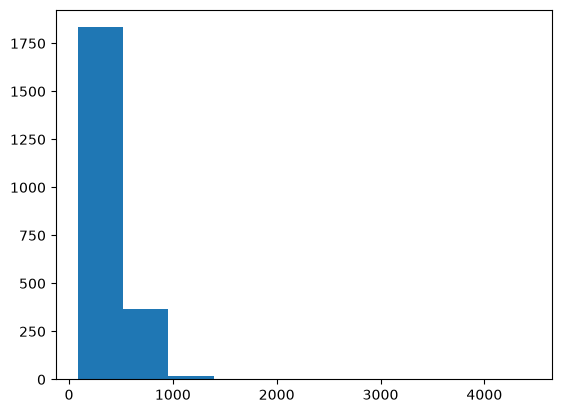

In [26]:
import matplotlib.pyplot as plt
plt.hist(lens)
np.max(lens)

In [27]:
np.max(lens)

np.int64(4432)

In [28]:
texts = [' '.join(a.split()[:100]) for a in df.text]

In [29]:
embeddings = featurizer(texts)

In [30]:
# list of length N, each element is 1 x T x D, but T is variable
# we only want to keep the first embedding vector
# (not like RNNs)
# embeddings = [np.array(e[0]).mean(axis=0) for e in embeddings]  # average
embeddings = [e[0][0] for e in embeddings]  # first

In [31]:
embeddings = np.array(embeddings)
embeddings.shape

(2225, 768)

In [32]:
from sklearn.neighbors import NearestNeighbors

In [33]:
model = NearestNeighbors(metric='cosine')
model.fit(embeddings)

,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'cosine'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [34]:
distances, indices = model.kneighbors(embeddings[10].reshape(1, -1))

In [35]:
distances

array([[9.99200722e-16, 7.08889138e-03, 8.23365060e-03, 9.57619866e-03,
        1.04166747e-02]])

In [36]:
indices

array([[  10,    0,  273, 2160,  279]])

In [37]:
df.iloc[10].text

"Ask Jeeves tips online ad revival\n\nAsk Jeeves has become the third leading online search firm this week to thank a revival in internet advertising for improving fortunes.\n\nThe firm's revenue nearly tripled in the fourth quarter of 2004, exceeding $86m (£46m). Ask Jeeves, once among the best-known names on the web, is now a relatively modest player. Its $17m profit for the quarter was dwarfed by the $204m announced by rival Google earlier in the week. During the same quarter, Yahoo earned $187m, again tipping a resurgence in online advertising.\n\nThe trend has taken hold relatively quickly. Late last year, marketing company Doubleclick, one of the leading providers of online advertising, warned that some or all of its business would have to be put up for sale. But on Thursday, it announced that a sharp turnaround had brought about an unexpected increase in profits. Neither Ask Jeeves nor Doubleclick thrilled investors with their profit news, however. In both cases, their shares fe

In [38]:
df.iloc[10].labels

'business'

In [39]:
df.iloc[0].text

'Ad sales boost Time Warner profit\n\nQuarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.\n\nThe firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.\n\nTime Warner said on Friday that it now owns 8% of search-engine Google. But its own internet business, AOL, had has mixed fortunes. It lost 464,000 subscribers in the fourth quarter profits were lower than in the preceding three quarters. However, the company said AOL\'s underlying profit before exceptional items rose 8% on the back of stronger internet advertising revenues. It hopes to increase subscribers by offering the online service free to TimeWarner internet customers and will try to sig

In [40]:
df.iloc[273].text

"Google shares fall as staff sell\n\nShares in Google have fallen 6.7% after employees and early investors in the web search took advantage of the first chance to sell their holdings.\n\nRestrictions were imposed ahead of its flotation in August, to prevent shares being dumped quickly onto the market. In one of the most closely-watched initial public offerings in stock market history, the US-based company sold 19.6 million shares at $85 each. Google shares have risen since but fell $12.33 on Tuesday to close at $172.55. The restriction - known as a lockup - is being eased piecemeal: in all, some 227 million additional shares will become free to trade by February 2005. Selling the shares could turn many of Google's workers into millionaires.\n\nThere were fears that the potential increase of shares in circulation from Tuesday would ease demand for stock. However, analysts say they expected most shareholders would be holding back from selling all their shares immediately, as Google's goo

In [41]:
df.iloc[273].labels

'business'

In [42]:
query = featurizer("TV and film")

In [43]:
len(query)

1

In [44]:
len(query[0])

5

In [45]:
len(query[0][0])

768

In [46]:
distances, indices = model.kneighbors(np.array(query[0][0]).reshape(1, -1))

In [47]:
distances

array([[0.02692949, 0.02692949, 0.02718368, 0.02872825, 0.02919898]])

In [48]:
indices

array([[2136, 1917,  846, 2183,  606]])

In [49]:
df.iloc[2136].text

'What high-definition will do to DVDs\n\nFirst it was the humble home video, then it was the DVD, and now Hollywood is preparing for the next revolution in home entertainment - high-definition.\n\nHigh-definition gives incredible, 3D-like pictures and surround sound. The DVD disks and the gear to play them will not be out for another year or so, and there at are still a number of issues to be sorted out. But when high-definition films do come out on the new format DVDs, it will profoundly change home entertainment. For Rick Dean, director of business development for digital content company THX, a high-definition future is an exciting prospect. He has worked on the Star Wars DVD trilogy, Finding Nemo, The Incredibles and Indiana Jones. "There was a time not so long ago when the film world and the video world were two completely separate worlds," he told the BBC News website.\n\n"The technology we are dealing with now means they are very much conjoined. "The film that we see in theatres 

In [50]:
df.iloc[2136].labels

'tech'